## Läs in data

Kode letar efter CSV-filen i projektets `data`-mapp, läser in den och sparar innehållet i `df`. Den hittar också projektmappen och skapar en `bilder`-mapp om den inte redan finns. 


In [1]:
import pandas as pd
from pathlib import Path
import sys

filnamn = "health_study_dataset.csv"
arbetsmapp = Path.cwd().resolve()

möjliga_filer = [
    mapp / "data" / filnamn
    for mapp in [arbetsmapp, *arbetsmapp.parents]
]

csv_fil = next(
    (fil for fil in möjliga_filer if fil.exists()),
    None
)

if csv_fil is None:
    raise FileNotFoundError(
        f"Hittade inte data/{filnamn}. Kontrollera filnamnet och mappstrukturen"
    )

projektrot = csv_fil.parent.parent
sys.path.insert(0, str(projektrot))

df = pd.read_csv(csv_fil)
bilder_mapp = projektrot/ "bilder"
bilder_mapp.mkdir(parents=True, exist_ok=True)

print(f"CSV-filen lästes in: {csv_fil}")
print(f"Antal rader och kolumner: {df.shape}")



CSV-filen lästes in: C:\Users\PC\Desktop\Hälsostudie\data\health_study_dataset.csv
Antal rader och kolumner: (800, 9)


In [2]:
from src.health_analyzer import HealthAnalyzer

analys = HealthAnalyzer(df, Path("../bilder"))

## Beskrivande statistik 

Här sammanfattas ålder, vikt, längd, systoliskt blodtryck och kolesterol med medelvärde, median, min och max. 
Funktionerna gör samma beräkningar som i Del 1, men statistik är nu samlad i en funktion så att det kan återanvändas. 

In [3]:
analys.descriptive_statistics()


,Medelvärde,Median,Min,Max
Ålder (år),49.43,50.00,18.0,90.00
Vikt (kg),73.41,73.20,33.7,114.40
Längd (cm),171.85,171.35,144.4,200.40
Systoliskt blodtryck (mmHg),149.18,149.40,106.8,185.90
Kolesterol (mmol/L),4.93,4.97,2.5,7.88


## Fördelning av systoliskt blodtryck 

Histogrammet visar hur deltagarnas blodtryck fördelar sig. Den streckade linjen markerar medelvärdet. Det skuggade området visar hur stor andel av deltagarna som har värde mellan 135 och 167 mmHg. 

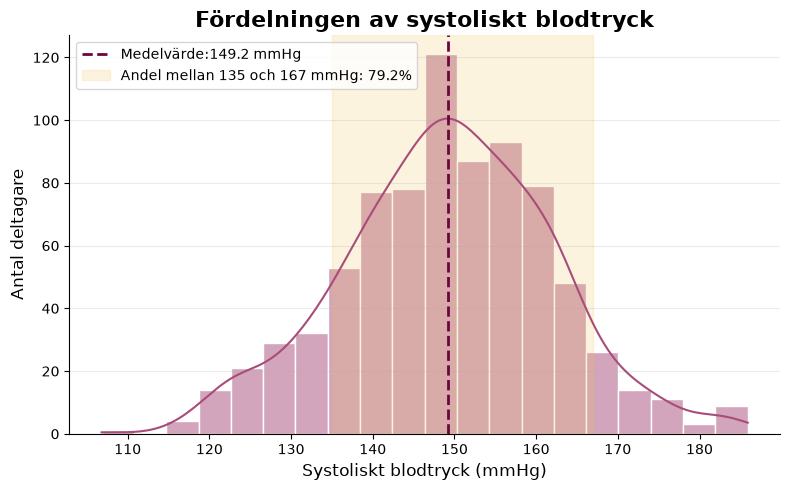

In [4]:
analys.plot_blood_pressure()

## Samband mellan ålder och systoliskt blodtryck

Punktdiagrammet visar varje deltagares ålder och blodtryck. Den räta linjen visar den övergripande trenden. 
Regressionen beräknas med Numpy och används här för att beskriva sambandet i datan. 

Ett samband i diagrammet visar inte att ålder orsakar en förändring i blodtrycket. 

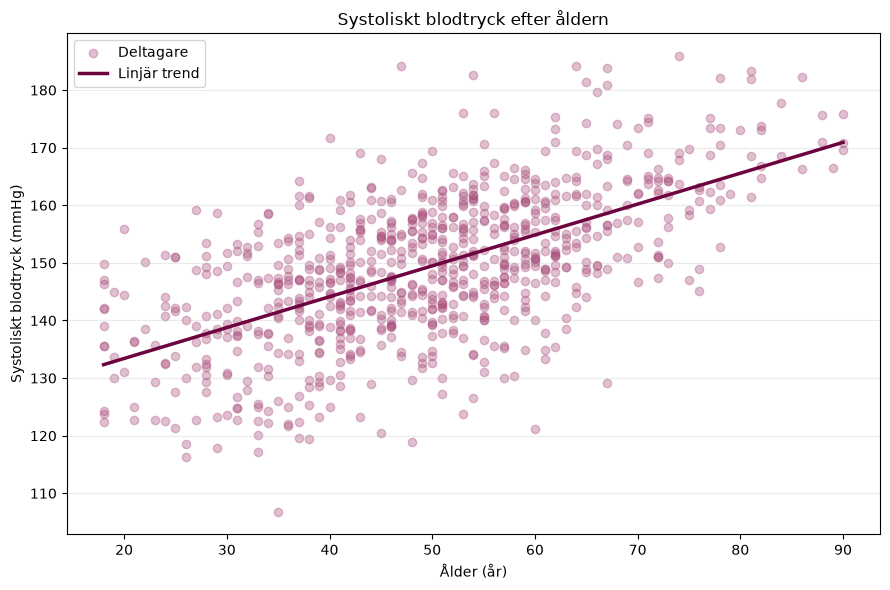

Lutning: 0.54 mmHg per år


In [5]:
resultat = analys.regression_bp_age()
print(f"Lutning: {resultat['lutning_mmHg_per_år']:.2f} mmHg per år")

## Tolkning

Modellens lutning är **0.54 mmHg per år**. Det betyder att modellens uppskattade blodtryck ökar med ungefär så mycket för varje extra år i ålder. Det beskriver ett samband i datasetet och visar inte att ålder orsakar förändringen.

## VG

## Multipel regression

Här undersöks hur ålder, vikt och kolesterol hänger ihop med blodtrycket. Alla tre faktorerna används samtidigt i beräkningen.

NumPy räknar ut en modell som försöker komma så nära deltagarnas faktiska blodtryck som möjligt.

R² visar hur stor del av skillnaderna i blodtryck modellen kan förklara. Resultatet gäller deltagarna i datan och visar inte att faktorerna orsakar förändringar i blodtrycket.

Källa: Kursmaterialet *Linjär regression*, Jupyter Notebook.

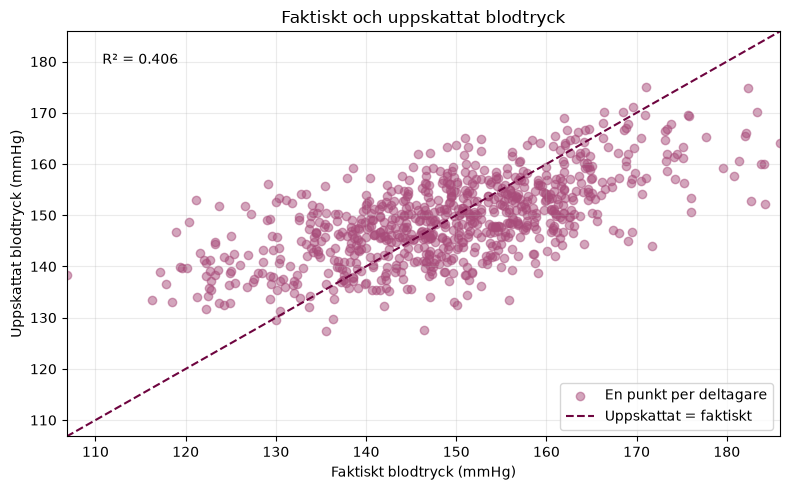

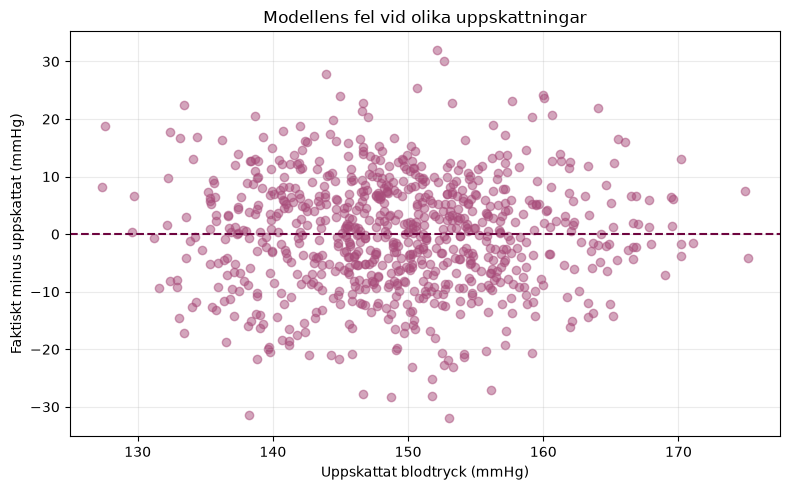

Koefficient för ålder: 0.53
Koefficient för vikt: 0.17
Koefficient för kolesterol: 0.43
R²: 0.406


In [6]:
resultat = analys.multiple_regression_bp()

print(f"Koefficient för ålder: {resultat['ålder']:.2f}")
print(f"Koefficient för vikt: {resultat['vikt']:.2f}")
print(f"Koefficient för kolesterol: {resultat['kolesterol']:.2f}")
print(f"R²: {resultat['r2']:.3f}")


## Tolkning av modellerna

### Faktiskt och uppskattat blodtryck

Varje punkt visar en deltagare. Punkter nära den streckade linjen betyder att modellens uppskattning ligger nära personens faktiska blodtryck. Ju längre från linjen en punkt ligger, desto större är skillnaden mellan uppskattningen och det faktiska värdet.

### Modellens fel

Residualen är skillnaden mellan det faktiska blodtrycket och modellens uppskattning. I residualdiagrammet visar nollinjen att uppskattningen stämde exakt. Punkter längre från nollinjen visar större fel. Ett tydligt mönster bland punkterna kan tyda på att modellen inte fångar hela sambandet.

### R²

R²-värdet är 0,406. Det betyder att modellen med ålder, vikt och kolesterol beskriver ungefär 41 % av variationen i blodtryck i detta dataset. Det betyder inte att modellen har 41 % rätt. Resultatet visar samband i datan, inte att faktorerna orsakar förändringar i blodtrycket.